## โจทย์

#### input
- ข้อมูลจาก https://github.com/wongnai/wongnai-corpus

#### Output
- visualization heatmap เรียกจากมากไปน้อย
- visualization word cloud
- performance test โดยการใช้ smooting แบบ +1

#### เครื่องมือ
- ใช้ Bayesian, pythainlp และ libery พื้นฐาน

## Import libery ต่าง ๆ

In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from pythainlp.tokenize import word_tokenize
from pythainlp.corpus.common import thai_stopwords

## นำเข้าข้อมูลมา Normalize

In [ ]:
# นำเข้าจาก csv (ไฟล์คั่นด้วยเครื่องหมาย ; และไม่มีหัวตาราง)
df = pd.read_csv('w_review_train.csv', sep=';', header=None, names=['review', 'rating'])

# สุ่มข้อมูลมา 2,000 แถว เพื่อให้ตัดคำภาษาไทยได้รวดเร็ว (ปรับจำนวนได้ตามต้องการ)
df = df.sample(n=2000, random_state=42).reset_index(drop=True)

print(f'จำนวนข้อมูลทั้งหมดที่ใช้: {len(df)} รีวิว')
df.head()

จำนวนข้อมูลทั้งหมดที่ใช้: 2000 รีวิว


,review,rating
0,ปกติไม่ค่อยทานขนมและของหวาน. แต่ก็ต้องยอมแพ้ใ...,5
1,ห้องอาหารโรงแรมฟอริดา เป็นห้องอาหารในโรงแรมที่...,4
2,ช่วงเวลาดีๆ ที่มีโปร 1 แถม 1 เช่นนี้ถ้าผ่านมาโ...,5
3,ร้อนแบบนี้ เราต้องหาอะไรดับร้อนกันสักหน่อย จะด...,4
4,ร้านเล็กๆในเขตกองเรือทุ่นระเบิดก่อนถึงป้อมพระจ...,4


In [ ]:
''' 
1. แยกคำไทย
2. ตัด stop word
3. จัดให้อยู่ในรูปที่นำไปใช้ได้ง่าย
'''
# ดึงชุดคำเชื่อม/คำฟุ่มเฟือยภาษาไทย (Stop words)
stop_words = set(thai_stopwords())

def normalize_text(text):
    # 1. แยกคำภาษาไทยด้วย engine 'newmm'
    words = word_tokenize(str(text), engine='newmm', keep_whitespace=False)
    
    # 2. ตัด stop word และกรองเฉพาะคำที่มีความยาวมากกว่า 1 ตัวอักษร
    clean_words = []
    for w in words:
        w = w.strip()
        if w not in stop_words and len(w) > 1 and not w.isnumeric():
            clean_words.append(w)
            
    return clean_words

# 3. จัดให้อยู่ในรูปคอลัมน์รายการคำ (tokens) เพื่อนำไปคำนวณความถี่และ Bayesian ต่อได้ง่าย
df['tokens'] = df['review'].apply(normalize_text)

# แสดงตัวอย่างตารางหลัง Normalize
df[['review', 'tokens', 'rating']].head()

,review,tokens,rating
0,ปกติไม่ค่อยทานขนมและของหวาน. แต่ก็ต้องยอมแพ้ใ...,"[ปกติ, ทาน, ขนม, หวา, น., ยอมแพ้, บิ, ซู, ที่น...",5
1,ห้องอาหารโรงแรมฟอริดา เป็นห้องอาหารในโรงแรมที่...,"[ห้องอาหาร, โรงแรม, ฟอ, ริ, ดา, ห้องอาหาร, โรง...",4
2,ช่วงเวลาดีๆ ที่มีโปร 1 แถม 1 เช่นนี้ถ้าผ่านมาโ...,"[ช่วงเวลา, ดี, โปร, แถม, โปรด, อย่า, ปล่อย, มั...",5
3,ร้อนแบบนี้ เราต้องหาอะไรดับร้อนกันสักหน่อย จะด...,"[ร้อน, แบบนี้, ต้องหา, ดับ, ร้อน, สักหน่อย, ดี...",4
4,ร้านเล็กๆในเขตกองเรือทุ่นระเบิดก่อนถึงป้อมพระจ...,"[ร้าน, เขต, กองเรือ, ทุ่นระเบิด, ป้อม, พระ, จุ...",4


In [ ]:
# ฟังก์ชันนับความถี่ของคำ (ใช้ Dictionary พื้นฐาน)
def count_words(word_list):
    counts = {}
    for word in word_list:
        if word in counts:
            counts[word] += 1
        else:
            counts[word] = 1
    return counts

# ฟังก์ชันดึงคำที่พบบ่อยสุด N อันดับแรก เรียงจากมากไปน้อย
def get_top_words(counts, top_n=10):
    # เรียงลำดับตามความถี่จากมากไปน้อย (reverse=True)
    sorted_words = sorted(counts.items(), key=lambda item: item[1], reverse=True)
    return sorted_words[:top_n]

# --- ทดสอบการทำงานของฟังก์ชันด้วยตัวอย่าง --- 
sample_words = ['อร่อย', 'มาก', 'บริการ', 'ดี', 'อร่อย', 'ราคา', 'แพง', 'อร่อย', 'บริการ', 'ช้า']
sample_counts = count_words(sample_words)
sample_top = get_top_words(sample_counts, top_n=3)

print('ตัวอย่างคำนำเข้า:', sample_words)
print('ผลลัพธ์จาก count_words():', sample_counts)
print('ผลลัพธ์จาก get_top_words(top_n=3):', sample_top)

ตัวอย่างคำนำเข้า: ['อร่อย', 'มาก', 'บริการ', 'ดี', 'อร่อย', 'ราคา', 'แพง', 'อร่อย', 'บริการ', 'ช้า']
ผลลัพธ์จาก count_words(): {'อร่อย': 3, 'มาก': 1, 'บริการ': 2, 'ดี': 1, 'ราคา': 1, 'แพง': 1, 'ช้า': 1}
ผลลัพธ์จาก get_top_words(top_n=3): [('อร่อย', 3), ('บริการ', 2), ('มาก', 1)]


## Training

### นับจำนวนคำที่ซ้ำกัน

In [ ]:
# แบ่งข้อมูลเป็นชุด Train 80% (1,600 รีวิว) และชุด Test 20% (400 รีวิว) สำหรับวัดผลภายหลัง
split_idx = int(len(df) * 0.8)
train_df = df.iloc[:split_idx].reset_index(drop=True)
test_df = df.iloc[split_idx:].reset_index(drop=True)

ratings = [1, 2, 3, 4, 5]
class_word_counts = {}   # เก็บ Dictionary ความถี่คำของแต่ละดาว (nk)
class_total_words = {}   # เก็บจำนวนคำทั้งหมดในแต่ละดาว (n)
class_priors = {}        # เก็บความน่าจะเป็นของแต่ละดาว P(vj)
vocab_set = set()        # เก็บคำศัพท์ที่ไม่ซ้ำทั้งหมด (Vocabulary)

for r in ratings:
    # ดึงเฉพาะรีวิวที่ได้ดาว r
    sub_df = train_df[train_df['rating'] == r]
    
    # รวมคำทั้งหมดในดาว r มาต่อกันเป็นรายการเดียว
    all_words_in_star = []
    for tokens in sub_df['tokens']:
        for w in tokens:
            all_words_in_star.append(w)
            vocab_set.add(w)
            
    # นับความถี่คำด้วยฟังก์ชัน count_words ที่เขียนเอง
    class_word_counts[r] = count_words(all_words_in_star)
    class_total_words[r] = len(all_words_in_star)
    class_priors[r] = len(sub_df) / len(train_df)

vocab = sorted(list(vocab_set))
vocab_size = len(vocab)

print(f'จำนวนคำศัพท์ที่ไม่ซ้ำทั้งหมด (|Vocabulary|): {vocab_size} คำ')
for r in ratings:
    print(f'{r} ดาว: มีคำทั้งหมด {class_total_words[r]:,} คำ | ตัวอย่างคำยอดฮิต: {get_top_words(class_word_counts[r], 3)}')

จำนวนคำศัพท์ที่ไม่ซ้ำทั้งหมด (|Vocabulary|): 11054 คำ
1 ดาว: มีคำทั้งหมด 1,034 คำ | ตัวอย่างคำยอดฮิต: [('ร้าน', 29), ('อาหาร', 18), ('ทาน', 18)]
2 ดาว: มีคำทั้งหมด 6,192 คำ | ตัวอย่างคำยอดฮิต: [('ร้าน', 193), ('สั่ง', 93), ('รสชาติ', 87)]
3 ดาว: มีคำทั้งหมด 34,083 คำ | ตัวอย่างคำยอดฮิต: [('ร้าน', 1356), ('อร่อย', 524), ('ดี', 510)]
4 ดาว: มีคำทั้งหมด 53,855 คำ | ตัวอย่างคำยอดฮิต: [('ร้าน', 1999), ('อร่อย', 1030), ('ดี', 705)]
5 ดาว: มีคำทั้งหมด 21,887 คำ | ตัวอย่างคำยอดฮิต: [('ร้าน', 712), ('อร่อย', 404), ('เมนู', 269)]


### laplace (+1) ให้กับข้อมูลเพื่อทำการ smooting

In [ ]:
# ทำ Laplace Smoothing (+1) ให้กับทุกคำใน Vocabulary ของแต่ละดาว
# ถ้าคำไหนเคยพบ nk ครั้ง -> กลายเป็น nk + 1
# ถ้าคำไหนไม่เคยพบเลย (0 ครั้ง) -> กลายเป็น 0 + 1 = 1 (ป้องกันความน่าจะเป็นเป็น 0)
smoothed_counts = {}
smoothed_totals = {}

for r in ratings:
    smoothed_counts[r] = {}
    for word in vocab:
        nk = class_word_counts[r].get(word, 0)
        smoothed_counts[r][word] = nk + 1
        
    # เมื่อบวก +1 ให้ทุกคำใน vocab ตัวหาร (จำนวนคำรวมของดาวนั้น) จึงต้องบวกด้วยจำนวนคำใน vocab
    smoothed_totals[r] = class_total_words[r] + vocab_size

# แสดงตัวอย่างเปรียบเทียบก่อนและหลังทำ +1 Smoothing ของคำว่า 'อร่อย'
example_word = 'อร่อย'
print(f"เปรียบเทียบจำนวนนับของคำว่า '{example_word}' ก่อนและหลังทำ Laplace (+1):")
for r in [5, 4, 3, 2, 1]:
    before = class_word_counts[r].get(example_word, 0)
    after = smoothed_counts[r].get(example_word, 1)
    print(f'  {r} ดาว: ก่อนบวก = {before:3d} ครั้ง  -->  หลังบวก (+1) = {after:3d} ครั้ง (ตัวหารรวม = {smoothed_totals[r]:,})')

เปรียบเทียบจำนวนนับของคำว่า 'อร่อย' ก่อนและหลังทำ Laplace (+1):
  5 ดาว: ก่อนบวก = 404 ครั้ง  -->  หลังบวก (+1) = 405 ครั้ง (ตัวหารรวม = 32,941)
  4 ดาว: ก่อนบวก = 1030 ครั้ง  -->  หลังบวก (+1) = 1031 ครั้ง (ตัวหารรวม = 64,909)
  3 ดาว: ก่อนบวก = 524 ครั้ง  -->  หลังบวก (+1) = 525 ครั้ง (ตัวหารรวม = 45,137)
  2 ดาว: ก่อนบวก =  78 ครั้ง  -->  หลังบวก (+1) =  79 ครั้ง (ตัวหารรวม = 17,246)
  1 ดาว: ก่อนบวก =  13 ครั้ง  -->  หลังบวก (+1) =  14 ครั้ง (ตัวหารรวม = 12,088)


### หาความน่าจะเป็นที่คำคำนั้นจะเป็นดาวนั้น ๆ เช่น พบคำว่า อร่อยใน 5 ดาวกี่ครั้ง 4 ดาวกี่ครั้ง ... 1 ดาวกี่ครั้ง ในรูปแบบของ จำนวนคำนั้น ๆ ที่พบ/จำนวนคำในดาวนั้น ๆ

In [ ]:
# คำนวณความน่าจะเป็น P(word | star) = (จำนวนคำนั้นที่พบ + 1) / (จำนวนคำทั้งหมดในดาวนั้น + |Vocabulary|)
word_probabilities = {}

for r in ratings:
    word_probabilities[r] = {}
    for word in vocab:
        word_probabilities[r][word] = smoothed_counts[r][word] / smoothed_totals[r]

# แสดงตารางเปรียบเทียบของคำว่า 'อร่อย' ในแต่ละดาว (5 ดาว -> 1 ดาว) ตามรูปแบบเศษส่วนและทศนิยม
summary_aroi = []
for r in [5, 4, 3, 2, 1]:
    nk = class_word_counts[r].get('อร่อย', 0)
    nk_plus_1 = smoothed_counts[r]['อร่อย']
    total_n = smoothed_totals[r]
    prob = word_probabilities[r]['อร่อย']
    summary_aroi.append({
        'ระดับดาว': f'{r} ดาว',
        'จำนวนที่พบจริง (nk)': nk,
        'หลัง Smoothing (nk + 1)': nk_plus_1,
        'จำนวนคำในดาวนั้น + |V|': total_n,
        'รูปแบบเศษส่วน': f'{nk_plus_1} / {total_n}',
        'ความน่าจะเป็น P(อร่อย|ดาว)': round(prob, 6)
    })

print("ตารางความน่าจะเป็นของคำว่า 'อร่อย' ในแต่ละระดับดาว (5 ดาว -> 1 ดาว):")
pd.DataFrame(summary_aroi)

ตารางความน่าจะเป็นของคำว่า 'อร่อย' ในแต่ละระดับดาว (5 ดาว -> 1 ดาว):


,ระดับดาว,จำนวนที่พบจริง (nk),หลัง Smoothing (nk + 1),จำนวนคำในดาวนั้น + |V|,รูปแบบเศษส่วน,ความน่าจะเป็น P(อร่อย|ดาว)
0,5 ดาว,404,405,32941,405 / 32941,0.012295
1,4 ดาว,1030,1031,64909,1031 / 64909,0.015884
2,3 ดาว,524,525,45137,525 / 45137,0.011631
3,2 ดาว,78,79,17246,79 / 17246,0.004581
4,1 ดาว,13,14,12088,14 / 12088,0.001158


## Output

### Visualization Heatmap

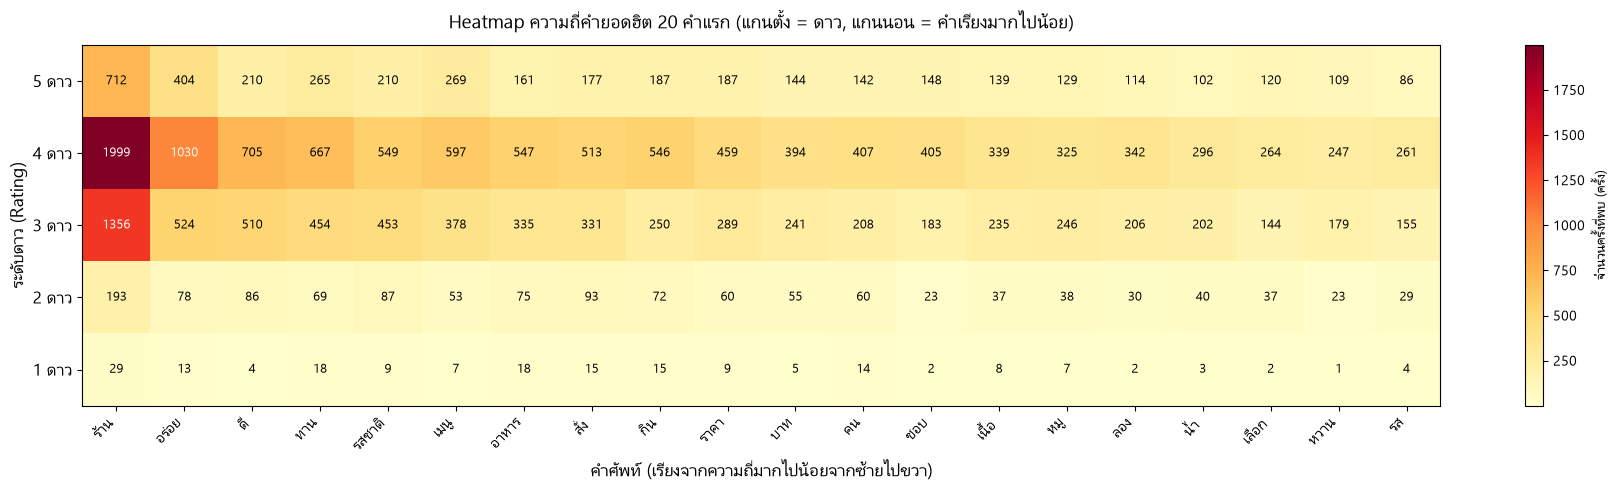

In [ ]:
# ตั้งค่าฟอนต์ภาษาไทยสำหรับกราฟ Matplotlib
plt.rcParams['font.family'] = ['Leelawadee UI', 'Tahoma']
plt.rcParams['axes.unicode_minus'] = False

# 1. รวมความถี่ของแต่ละคำจากทุกดาว เพื่อหาคำที่พบบ่อยที่สุด
total_word_counts = {}
for r in ratings:
    for word, cnt in class_word_counts[r].items():
        total_word_counts[word] = total_word_counts.get(word, 0) + cnt

# 2. ดึงคำที่พบบ่อยสุด 30 อันดับแรก เรียงจากมากไปน้อย (แกนนอนจะแสดงครบทุกคำชัดเจน ไม่เบียดทับกัน)
TOP_N = 20
top_words_list = get_top_words(total_word_counts, top_n=TOP_N)
word_labels = [item[0] for item in top_words_list]

# 3. สร้างเมทริกซ์ (แกนตั้ง = 5 ดาว -> 1 ดาว, แกนนอน = คำยอดฮิต 30 คำ เรียงมากไปน้อย)
star_rows = [5, 4, 3, 2, 1]
heatmap_matrix = []
for r in star_rows:
    row = [class_word_counts[r].get(w, 0) for w in word_labels]
    heatmap_matrix.append(row)

heatmap_matrix = np.array(heatmap_matrix)

# 4. วาดกราฟ Heatmap
fig, ax = plt.subplots(figsize=(18, 5))
im = ax.imshow(heatmap_matrix, cmap='YlOrRd', aspect='auto')

# แกนตั้ง (Y): ระดับดาว
ax.set_yticks(range(len(star_rows)))
ax.set_yticklabels([f'{r} ดาว' for r in star_rows], fontsize=12)
ax.set_ylabel('ระดับดาว (Rating)', fontsize=13)

# แกนนอน (X): รายชื่อคำ 30 คำ เรียงจากมากไปน้อยจากซ้ายไปขวา
ax.set_xticks(range(len(word_labels)))
ax.set_xticklabels(word_labels, rotation=45, ha='right', fontsize=11)
ax.set_xlabel('คำศัพท์ (เรียงจากความถี่มากไปน้อยจากซ้ายไปขวา)', fontsize=13)

# ใส่ตัวเลขจำนวนครั้งกำกับในช่อง
max_val = heatmap_matrix.max()
for i in range(len(star_rows)):
    for j in range(len(word_labels)):
        val = heatmap_matrix[i, j]
        text_color = 'white' if val > max_val * 0.5 else 'black'
        ax.text(j, i, str(val), ha='center', va='center', color=text_color, fontsize=9)

fig.colorbar(im, ax=ax, label='จำนวนครั้งที่พบ (ครั้ง)')
ax.set_title(f'Heatmap ความถี่คำยอดฮิต {TOP_N} คำแรก (แกนตั้ง = ดาว, แกนนอน = คำเรียงมากไปน้อย)', fontsize=14, pad=12)
plt.tight_layout()
plt.show()

### Visualization Word Cloud

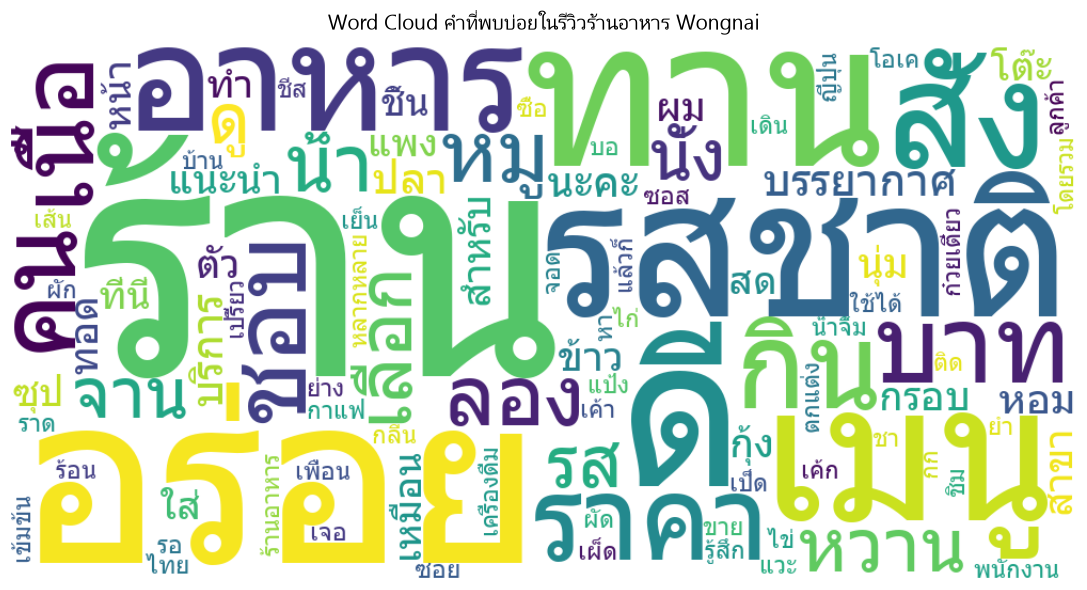

In [ ]:
from wordcloud import WordCloud

# สร้าง Word Cloud จาก Dictionary ความถี่คำ (total_word_counts) โดยใช้ฟอนต์ภาษาไทยของ Windows
wc = WordCloud(
    font_path='C:/Windows/Fonts/tahoma.ttf',
    width=1000,
    height=500,
    background_color='white',
    max_words=100,
    colormap='viridis'
).generate_from_frequencies(total_word_counts)

# แสดงภาพ Word Cloud
plt.figure(figsize=(12, 6))
plt.imshow(wc, interpolation='bilinear')
plt.axis('off')
plt.title('Word Cloud คำที่พบบ่อยในรีวิวร้านอาหาร Wongnai', fontsize=15, pad=12)
plt.tight_layout()
plt.show()

### Performance Test

In [ ]:
# ฟังก์ชันทำนายระดับดาวด้วย Naïve Bayes (ใช้ความน่าจะเป็นที่ทำ Laplace Smoothing +1 แล้ว)
# ใช้ค่า log เพื่อป้องกันปัญหาตัวเลขทศนิยมคูณกันหลายครั้งแล้วเข้าใกล้ 0 (Underflow)
def predict_rating(tokens):
    best_star = None
    best_score = -float('inf')
    
    for r in ratings:
        # เริ่มต้นด้วยค่า log ของ Prior P(vj)
        score = np.log(class_priors[r])
        
        # บวกค่า log ของความน่าจะเป็นของแต่ละคำ P(wk | vj)
        for w in tokens:
            if w in word_probabilities[r]:
                prob = word_probabilities[r][w]
            else:
                # กรณีเจอคำใหม่ในชุด Test ที่ไม่เคยปรากฏในชุด Train เลย ใช้ค่า +1 Smoothing
                prob = 1 / smoothed_totals[r]
            score += np.log(prob)
            
        # เลือกดาวที่ได้คะแนนความน่าจะเป็นสูงสุด (MAP)
        if score > best_score:
            best_score = score
            best_star = r
            
    return best_star

# นำโมเดลไปทดสอบกับชุดข้อมูล Test (400 รีวิว)
test_df['predicted'] = test_df['tokens'].apply(predict_rating)

# คำนวณความแม่นยำ (Accuracy)
correct_exact = (test_df['predicted'] == test_df['rating']).sum()
accuracy_exact = (correct_exact / len(test_df)) * 100

# คำนวณความแม่นยำกรณีคลาดเคลื่อนไม่เกิน 1 ดาว (เช่น จริง 4 ดาว ทาย 4 หรือ 5 ดาว)
correct_near = (np.abs(test_df['predicted'] - test_df['rating']) <= 1).sum()
accuracy_near = (correct_near / len(test_df)) * 100

print(f'จำนวนข้อมูลชุดทดสอบทั้งหมด: {len(test_df)} รีวิว')
print(f'ทายตรงเป๊ะ (Exact Accuracy): {correct_exact}/{len(test_df)} รีวิว ({accuracy_exact:.2f}%)')
print(f'ทายใกล้เคียง ±1 ดาว (Within ±1 Star Accuracy): {correct_near}/{len(test_df)} รีวิว ({accuracy_near:.2f}%)')

# แสดงตาราง Confusion Matrix เปรียบเทียบดาวจริง กับ ดาวที่ทำนายได้
conf_matrix = pd.crosstab(
    test_df['rating'],
    test_df['predicted'],
    rownames=['ดาวจริง (Actual)'],
    colnames=['ดาวที่ทำนาย (Predicted)']
).reindex(index=ratings, columns=ratings, fill_value=0)

print('\nตาราง Confusion Matrix:')
display(conf_matrix)

# แสดงตัวอย่างผลการทำนาย 10 รีวิวแรกในชุด Test
test_df[['review', 'rating', 'predicted']].head(10)

จำนวนข้อมูลชุดทดสอบทั้งหมด: 400 รีวิว
ทายตรงเป๊ะ (Exact Accuracy): 206/400 รีวิว (51.50%)
ทายใกล้เคียง ±1 ดาว (Within ±1 Star Accuracy): 370/400 รีวิว (92.50%)

ตาราง Confusion Matrix:


ดาวที่ทำนาย (Predicted),1,2,3,4,5
ดาวจริง (Actual),,,,,
1,0,0,0,2,0
2,1,0,7,9,0
3,0,0,50,59,6
4,0,1,34,147,11
5,0,0,12,52,9


,review,rating,predicted
0,ไอติมโฮมเมทที่มีหลายรสให้เลือก ไปแต่ล่ะวันรสที...,4,4
1,ชอบน๊ร้านนี้ พึงไปกินมา ถือว่าคุ้ม กุ้งสดมากเน...,4,4
2,ก่อนที่จะมาทานนี้ เคยทานที่สาขาแรก ตอนเอารถไปล...,3,3
3,ร้านชิวๆ บรรยากาศดีติดทะเล อาหารทะเลสดอร่อยมาก...,4,4
4,ร้านนี้เด็ดจริงๆ อาหารทะเลหลากหลายแบบ ใครชอบอา...,5,4
5,หากท่านใดที่ชื่นชอบการทานอาหรญี่ปุ่นแบบไม่อั้น...,5,4
6,ออกจากท่าเรือชุมพรแล้วขับรถต่อมาอีกนิด ร้านอาห...,4,4
7,สำหรับใครที่อ่านหนังสือที่บ้านแล้วหลับ อยากได้...,3,3
8,มาเพชรบุรีทีไรเป็นปัญหาทุกที หาร้านอาหารอร่อยๆ...,5,4
9,"บ่ฮู้เจ้าเดียวกันรึป่าวนะเจ้า แต้ว่าชื่อ""ขนมคร...",4,2
